/usr/lib/python3/dist-packages/scipy/__init__.py:146: UserWarning: A NumPy version >=1.17.3 and <1.25.0 is required for this version of SciPy (detected version 1.26.4
  warnings.warn(f"A NumPy version >={np_minversion} and <{np_maxversion}"
/home/ziqih2/.local/lib/python3.10/site-packages/pandas/core/computation/expressions.py:21: UserWarning: Pandas requires version '2.8.4' or newer of 'numexpr' (version '2.8.1' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED
/home/ziqih2/.local/lib/python3.10/site-packages/pandas/core/arrays/masked.py:60: UserWarning: Pandas requires version '1.3.6' or newer of 'bottleneck' (version '1.3.2' currently installed).
  from pandas.core import (


positive trajectory accepted after 5 draw(s)
minimum true state = 0.0345
Parameter estimates and NLL at each estimate
Method                          phi_hat   abs phi err     NLL(phi_hat)
Analytic global               0.7139806     0.1360194      823.7221465
SARIMAX filter                0.7139803     0.1360197      823.7221516
SARIMAX smoothed-state        0.7139806     0.1360194      823.7221465
Constrained marginal          0.7261667     0.1238333      832.2546781
True phi = 0.8500000; constrained grid step = 0.01283
Note: absolute NLLs of different probabilistic models need not be directly comparable as estimation errors.
Method                        state RMSE   vs obs RMSE    min state
Analytic global                 0.377874      0.609597    -1.452789
SARIMAX filter                  0.377874      0.609597    -1.452789
SARIMAX smoothed-state          0.377874      0.609597    -1.452789
Constrained marginal            0.120648      0.800083     0.000000
Raw observations         

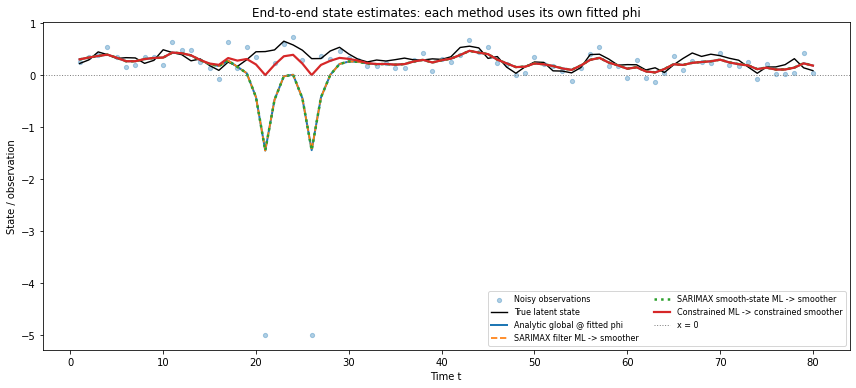

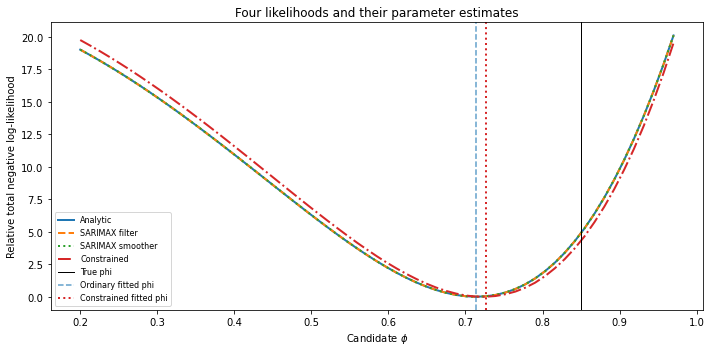

Max ordinary analytic-filter NLL gap: 6.882031811983325e-06
Max ordinary analytic-smoother NLL gap: 4.547473508864641e-13
Gaussian-demo phi = 0.702028
Robust-demo phi = 0.574501


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize_scalar

from ar1_student_t_robust.config import (
    N,
    mu,
    phi_true,
    q,
    r,
    x0,
    MC,
    rng,
    rng_mc,
    eps_prior,
    eps_post,
    nu,
    ADD_OUTLIERS,
    bounds,
    opts,
)
from ar1_student_t_robust.data_generation import draw_positive_trajectory
from ar1_student_t_robust.global_model import analytic_nll, global_smooth_state
from ar1_student_t_robust.sarimax_model import sarimax_filter_nll, sarimax_smoothed_state, smooth_state_nll
from ar1_student_t_robust.inequality_model import constrained_nll, constrained_smooth_state
from ar1_student_t_robust.robust_model import ar1_B_b, gaussian_nll_for_data, robust_laplace_nll

np.set_printoptions(precision=6, suppress=True)

# ---------------------------
# Generate data
# ---------------------------

x_true, attempts = draw_positive_trajectory(rng)
z = x_true + r * rng.normal(size=N)
z[20] = -5
z[25] = -5
tgrid = np.arange(1, N + 1)

print(f"positive trajectory accepted after {attempts} draw(s)")
print(f"minimum true state = {x_true.min():.4f}")

# ---------------------------
# Parameter estimation
# ---------------------------

opt_analytic = minimize_scalar(lambda phi: analytic_nll(phi, z), bounds=bounds, method="bounded", options=opts)
opt_filter = minimize_scalar(lambda phi: sarimax_filter_nll(phi, z), bounds=bounds, method="bounded", options=opts)
opt_smooth = minimize_scalar(lambda phi: smooth_state_nll(phi, z), bounds=bounds, method="bounded", options=opts)

phi_grid = np.linspace(0.20, 0.97, 61)
constrained_grid_nll = np.array([constrained_nll(p, z) for p in phi_grid])
idx_c = int(np.argmin(constrained_grid_nll))
phi_hat_c = float(phi_grid[idx_c])

phi_hats = {
    "Analytic global": float(opt_analytic.x),
    "SARIMAX filter": float(opt_filter.x),
    "SARIMAX smoothed-state": float(opt_smooth.x),
    "Constrained marginal": phi_hat_c,
}

nll_functions = {
    "Analytic global": lambda p: analytic_nll(p, z),
    "SARIMAX filter": lambda p: sarimax_filter_nll(p, z),
    "SARIMAX smoothed-state": lambda p: smooth_state_nll(p, z),
    "Constrained marginal": lambda p: constrained_nll(p, z),
}

print("Parameter estimates and NLL at each estimate")
print(f"{'Method':27s} {'phi_hat':>11s} {'abs phi err':>13s} {'NLL(phi_hat)':>16s}")
for name, p in phi_hats.items():
    print(f"{name:27s} {p:11.7f} {abs(p-phi_true):13.7f} {nll_functions[name](p):16.7f}")
print(f"True phi = {phi_true:.7f}; constrained grid step = {phi_grid[1]-phi_grid[0]:.5f}")
print("Note: absolute NLLs of different probabilistic models need not be directly comparable as estimation errors.")

# ---------------------------
# State comparison
# ---------------------------

states = {
    "Analytic global": global_smooth_state(phi_hats["Analytic global"], z),
    "SARIMAX filter": sarimax_smoothed_state(phi_hats["SARIMAX filter"], z),
    "SARIMAX smoothed-state": sarimax_smoothed_state(phi_hats["SARIMAX smoothed-state"], z),
    "Constrained marginal": constrained_smooth_state(phi_hats["Constrained marginal"], z),
}

def rmse(a, b):
    return float(np.sqrt(np.mean((np.asarray(a) - np.asarray(b)) ** 2)))

print(f"{'Method':27s} {'state RMSE':>12s} {'vs obs RMSE':>13s} {'min state':>12s}")
for name, xs in states.items():
    print(f"{name:27s} {rmse(xs, x_true):12.6f} {rmse(xs, z):13.6f} {np.min(xs):12.6f}")
print(f"{'Raw observations':27s} {rmse(z, x_true):12.6f} {'0.000000':>13s} {np.min(z):12.6f}")

plt.figure(figsize=(12, 5.5))
plt.scatter(tgrid, z, s=18, alpha=0.35, label="Noisy observations")
plt.plot(tgrid, x_true, color="black", linewidth=1.4, label="True latent state")
plt.plot(tgrid, states["Analytic global"], linewidth=2, label="Analytic global @ fitted phi")
plt.plot(tgrid, states["SARIMAX filter"], "--", linewidth=1.7, label="SARIMAX filter ML -> smoother")
plt.plot(tgrid, states["SARIMAX smoothed-state"], ":", linewidth=2.5, label="SARIMAX smooth-state ML -> smoother")
plt.plot(tgrid, states["Constrained marginal"], linewidth=2.2, label="Constrained ML -> constrained smoother")
plt.axhline(0, linestyle=":", linewidth=1, color="gray", label="x = 0")
plt.xlabel("Time t")
plt.ylabel("State / observation")
plt.title("End-to-end state estimates: each method uses its own fitted phi")
plt.legend(fontsize=8, ncol=2)
plt.tight_layout()
plt.show()

# ---------------------------
# Likelihood curves
# ---------------------------

a_curve = np.array([analytic_nll(p, z) for p in phi_grid])
f_curve = np.array([sarimax_filter_nll(p, z) for p in phi_grid])
s_curve = np.array([smooth_state_nll(p, z) for p in phi_grid])

plt.figure(figsize=(10, 5))
for label, arr, style in [
    ("Analytic", a_curve, "-"),
    ("SARIMAX filter", f_curve, "--"),
    ("SARIMAX smoother", s_curve, ":"),
    ("Constrained", constrained_grid_nll, "-."),
]:
    plt.plot(phi_grid, arr - arr.min(), style, linewidth=2, label=label)
plt.axvline(phi_true, color="black", linewidth=1, label="True phi")
plt.axvline(phi_hats["Analytic global"], color="tab:blue", linestyle="--", alpha=0.7, label="Ordinary fitted phi")
plt.axvline(phi_hat_c, color="tab:red", linestyle=":", linewidth=2, label="Constrained fitted phi")
plt.xlabel(r"Candidate $\phi$")
plt.ylabel("Relative total negative log-likelihood")
plt.title("Four likelihoods and their parameter estimates")
plt.legend(fontsize=8)
plt.tight_layout()
plt.show()
print("Max ordinary analytic-filter NLL gap:", np.max(np.abs(a_curve - f_curve)))
print("Max ordinary analytic-smoother NLL gap:", np.max(np.abs(a_curve - s_curve)))

# ---------------------------
# Robust Student-t extension
# ---------------------------

z_demo = z.copy()
if ADD_OUTLIERS:
    outlier_indices = np.array([12, 38, 62])
    z_demo[outlier_indices] += np.array([0.75, -0.85, 0.80])

opt_gaussian_demo = minimize_scalar(lambda phi: gaussian_nll_for_data(phi, z_demo), bounds=(0.05, 0.98), method="bounded")
opt_robust_demo = minimize_scalar(lambda phi: robust_laplace_nll(phi, z_demo, nu), bounds=(0.05, 0.98), method="bounded", options={"xatol": 1e-4})

phi_g = opt_gaussian_demo.x
phi_t = opt_robust_demo.x
B_g, b_g = ar1_B_b(phi_g)
J_g = B_g.T @ B_g / q**2 + np.eye(N) / r**2
x_g = np.linalg.solve(J_g, B_g.T @ b_g / q**2 + z_demo / r**2)

print(f"Gaussian-demo phi = {phi_g:.6f}")
print(f"Robust-demo phi = {phi_t:.6f}")